# Maternal Health Risk Classification Using Machine Learning

### 1. Introduction

I choose the maternal health risk dataset because I wanted to explore how machine learning can be used to analyze the health data. The dataset includes measurements such as age, blood pressure, blood sugar, body temperature and heart rate. My aim is to explore these measurements and use them to classify maternal health risk into three levels: low, mid and high.

In [1]:
import sys
print(sys.executable)
print(sys.version)

/opt/miniconda3/envs/ml-ca1/bin/python
3.11.18 (main, Oct 26 2026, 18:15:19) [Clang 20.1.8 ]


In [2]:
import numpy as np
print(np.__version__)
print(np.__file__)

1.26.4
/opt/miniconda3/envs/ml-ca1/lib/python3.11/site-packages/numpy/__init__.py


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Success!")

Success!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import os

print(os.getcwd())
print(os.listdir())

/Users/jmuji/Documents/GitHub/ML_CA1
['Munkhzaya_ML_Sept26 .ipynb', '.ipynb_checkpoints', '.git', 'Maternal Health Risk Data Set.csv']


In [6]:
df = pd.read_csv('/Users/jmuji/Documents/GitHub/ML_CA1/Maternal Health Risk Data Set.csv')

In [7]:
df.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [8]:
df.shape

(1014, 7)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


In [10]:
df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


### 2. Data Cleaning

In [11]:
df.isnull().sum()

Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

In [12]:
df.duplicated().sum()

562

In [13]:
df[df.duplicated(keep=False)].head(10)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
1,35,140,90,13.00,98.0,70,high risk
2,29,90,70,8.00,100.0,80,high risk
3,30,140,85,7.00,98.0,70,high risk
4,35,120,60,6.10,98.0,76,low risk
5,23,140,80,7.01,98.0,70,high risk
6,23,130,70,7.01,98.0,78,mid risk
7,35,85,60,11.00,102.0,86,high risk
8,32,120,90,6.90,98.0,70,mid risk
9,42,130,80,18.00,98.0,70,high risk
11,19,120,80,7.00,98.0,70,mid risk


In [14]:
df["RiskLevel"].value_counts()

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

In [15]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Check the result
print(df.shape)
print(df.duplicated().sum())

(452, 7)
0


In [16]:
df["RiskLevel"].value_counts()

RiskLevel
low risk     234
high risk    112
mid risk     106
Name: count, dtype: int64

## 3. Exploratory Data Analysis (EDA)

In this section, I explored the dataset before building the machine learning models. I looked at the distribution of age and blood sugar, and examined how these measurements relate to other health variables.

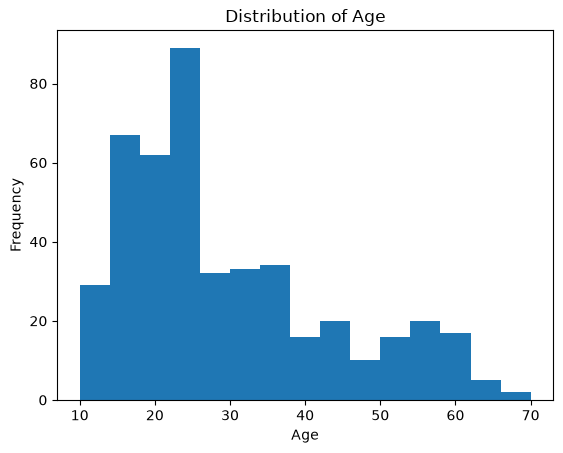

In [17]:
plt.hist(df['Age'], bins = 15)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

### The histogram shows that most individuals are between 15 and 30 years old. The number of observations generally decreases as age increases. The distribution is right-skewed.

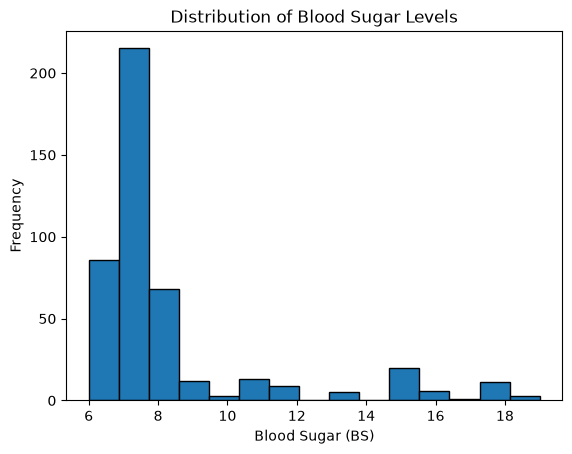

In [18]:
# Check the distribution of blood sugar levels
plt.hist(df['BS'], bins = 15, edgecolor = 'black')
plt.title('Distribution of Blood Sugar Levels')
plt.xlabel('Blood Sugar (BS)')
plt.ylabel('Frequency')
plt.show()

### Most blood sugar values are concentrated around 7–8. Higher values are less common, and the distribution is right-skewed.

In [19]:
#to check the 10 highest BS values
df.nlargest(10, 'BS')[['Age', 'BS', 'SystolicBP', 'DiastolicBP', 'RiskLevel']]

,Age,BS,SystolicBP,DiastolicBP,RiskLevel
116,40,19.0,160,100,high risk
120,55,19.0,140,95,high risk
233,35,19.0,85,60,high risk
9,42,18.0,130,80,high risk
20,40,18.0,140,100,high risk
103,42,18.0,140,100,high risk
112,55,18.0,140,100,high risk
117,32,18.0,140,90,high risk
163,40,18.0,140,100,high risk
232,55,18.0,120,90,high risk


In [20]:
#to check the average BS by age
age_bs = df.groupby('Age')['BS'].mean()

print(age_bs.sort_values(ascending = False).head(10))

Age
43    17.000000
44    16.000000
63    15.000000
54    13.500000
56    13.000000
50    12.373333
40    12.125000
46    12.000000
48    12.000000
37    11.000000
Name: BS, dtype: float64


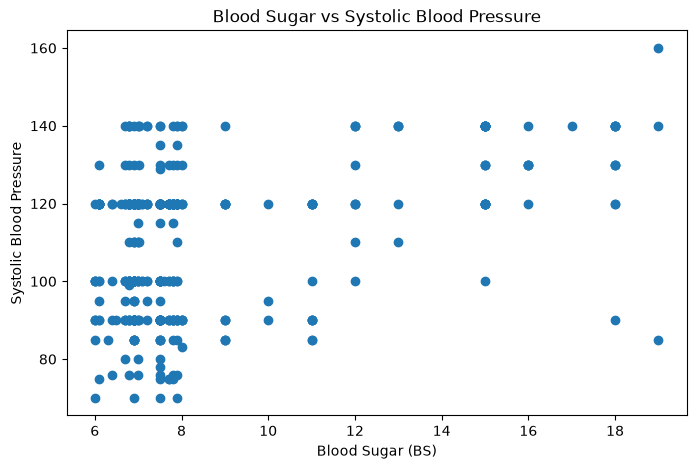

In [21]:
#to visualise the relationship between BS and blood pressure
plt.figure(figsize = (8, 5))

plt.scatter(df['BS'], df['SystolicBP'])

plt.title('Blood Sugar vs Systolic Blood Pressure')
plt.xlabel('Blood Sugar (BS)')
plt.ylabel('Systolic Blood Pressure')

plt.show()

In [22]:
#to check the correlation between BS and systolic blood pressure
df['BS'].corr(df['SystolicBP'])

0.34753395647234264

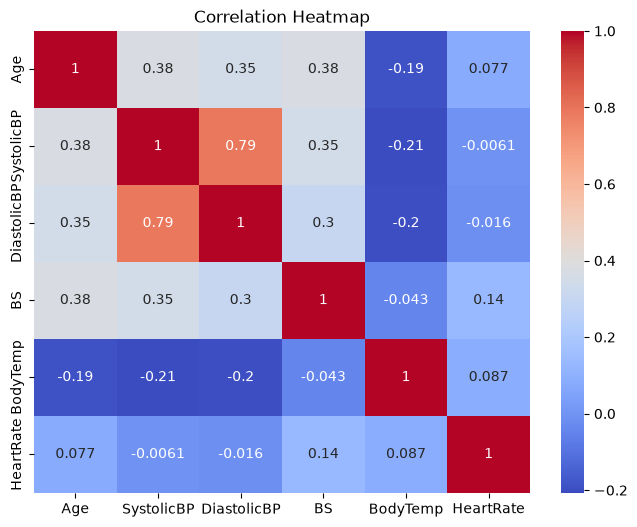

In [23]:
# Check correlations between numerical features
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### SystolicBP and DiastolicBP have a strong positive correlation (0.79). Age has a moderate positive correlation with blood sugar (0.38). Most other variables show weak or moderate correlations.

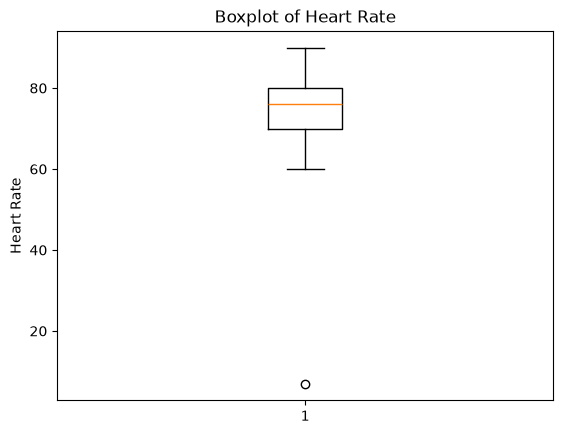

In [24]:
# Check possible outliers in heart rate
plt.boxplot(df['HeartRate'])
plt.title('Boxplot of Heart Rate')
plt.ylabel('Heart Rate')
plt.show()

### Most heart rate values are between 70 and 80 bpm. One unusually low value of 7 bpm appears as an outlier and needs further checking.

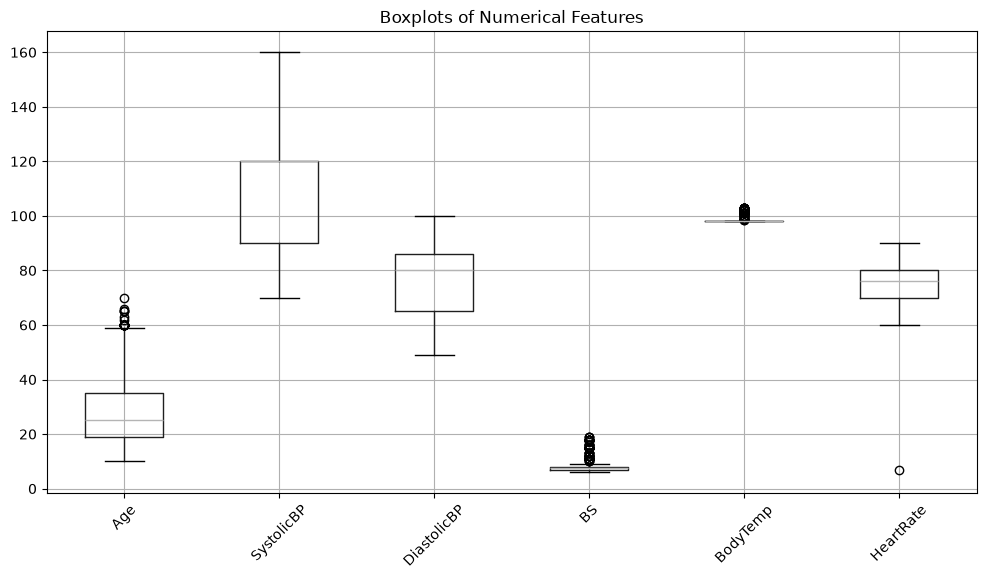

In [25]:
# Check possible outliers in all numerical features
plt.figure(figsize = (12, 6))
df.drop('RiskLevel', axis = 1).boxplot()
plt.title('Boxplots of Numerical Features')
plt.xticks(rotation = 45)
plt.show()

In [26]:
# Check records with an unusually low heart rate
df[df['HeartRate'] == 7]

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
342,16,120,75,7.9,98.0,7,low risk


In [27]:
# Count unusually low heart rate values
df[df['HeartRate'] == 7].shape[0]

1

In [28]:
# Remove the unrealistic heart rate value
df = df[df['HeartRate'] != 7].reset_index(drop=True)

# Check the dataset size
df.shape

(451, 7)

#### One unusually low heart rate value 7 bpm was found and removed because it was likely a data entry error. However, I kept the outliers in the other features because they might be real values rather than errors.

## 4. Machine Learning Model Development

In [29]:
# Select input features (X) and target variable (y)
X = df.drop('RiskLevel', axis=1)
y = df['RiskLevel']

# Check the size of X and y
print("Features:", X.shape)
print("Target:", y.shape)

Features: (451, 6)
Target: (451,)


In [30]:
# Display the first five rows of features
X.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
0,25,130,80,15.0,98.0,86
1,35,140,90,13.0,98.0,70
2,29,90,70,8.0,100.0,80
3,30,140,85,7.0,98.0,70
4,35,120,60,6.1,98.0,76


In [31]:
# Display the first five target values
y.head()

0    high risk
1    high risk
2    high risk
3    high risk
4     low risk
Name: RiskLevel, dtype: object

In [32]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42)

# Check the size of training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (428, 6)
Testing features: (23, 6)
Training target: (428,)
Testing target: (23,)


### Decision Tree Classifier

In [33]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier 

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(criterion='gini', max_depth = 4, random_state = 42)

# Train the model
dt_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [34]:
# Predict risk levels using the test data
y_pred_dt = dt_model.predict(X_test)

# Display predictions
y_pred_dt

array(['low risk', 'low risk', 'low risk', 'low risk', 'mid risk',
       'high risk', 'high risk', 'high risk', 'low risk', 'low risk',
       'high risk', 'low risk', 'low risk', 'low risk', 'high risk',
       'low risk', 'high risk', 'low risk', 'low risk', 'low risk',
       'low risk', 'high risk', 'mid risk'], dtype=object)

In [35]:
# Split the dataset using 5% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42)

In [36]:
# Import evaluation metrics
from sklearn import metrics

# Calculate Decision Tree accuracy
print("Decision Tree Accuracy (5%):", metrics.accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy (5%): 0.5652173913043478


### Random Forest Classifier

In [37]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)

# Train the model
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [38]:
# Predict risk levels using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Calculate Random Forest accuracy
print("Random Forest Accuracy (5%):", metrics.accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy (5%): 0.5652173913043478


###  Model Comparison Using Different Data Splits
#### 15% Test Split

In [39]:
# Split the dataset using 15% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42)

# Check training and testing sizes
print(X_train.shape)
print(X_test.shape)

(383, 6)
(68, 6)


In [40]:
# Train Decision Tree using 15% test split
dt_model.fit(X_train, y_train)

# Predict and calculate accuracy
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy (15%):",
      metrics.accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy (15%): 0.6029411764705882


In [41]:
# Train Random Forest using 15% test split
rf_model.fit(X_train, y_train)

# Predict and calculate accuracy
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy (15%):", metrics.accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy (15%): 0.5882352941176471


#### 25% Test Split

In [42]:
# Split the dataset using 25% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

# Check training and testing sizes
print(X_train.shape)
print(X_test.shape)

(338, 6)
(113, 6)


In [43]:
# Train Decision Tree using 25% test split
dt_model.fit(X_train, y_train)

# Predict and calculate accuracy
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy (25%):", metrics.accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy (25%): 0.6460176991150443


In [44]:
# Train Random Forest using 25% test split
rf_model.fit(X_train, y_train)

# Predict and calculate accuracy
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy (25%):", metrics.accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy (25%): 0.5752212389380531


I used Decision Tree and Random Forest models with three different test sizes: 5%, 15%, and 25%. The Decision Tree accuracy increased from 56.52% to 60.29% and then to 64.60%. On the other hand, Random Forest showed more stable results, ranging from 56.52% to 58.82%.

I think these differences may be related to the amount of data used for training and testing. As the test size increased, the training data became smaller, which may have affected the results. Random Forest may have been more stable because it combines predictions from several decision trees. However, Decision Tree performed better in this experiment, especially with 25% test data. I cannot say which model is better overall based on these results alone, so cross-validation is needed to check their performance more reliably.

### Cross-Validation

In [45]:
#Import cross-validation function
from sklearn.model_selection import cross_val_score

# Perform 10-fold cross-validation for Decision Tree
dt_cv_scores = cross_val_score(dt_model, X_train, y_train, cv = 10, scoring = 'accuracy')

# Display accuracy for each fold
print("Decision Tree CV Scores:", dt_cv_scores)

Decision Tree CV Scores: [0.70588235 0.70588235 0.70588235 0.61764706 0.82352941 0.73529412
 0.73529412 0.76470588 0.72727273 0.75757576]


In [46]:
# Calculate the mean cross-validation accuracy
mean_dt_cv = np.mean(dt_cv_scores)

print("Decision Tree Mean CV Accuracy:", mean_dt_cv)

Decision Tree Mean CV Accuracy: 0.7278966131907308


In [47]:
# Perform 10-fold cross-validation for Random Forest
rf_cv_scores = cross_val_score(rf_model, X_train, y_train, cv = 10, scoring = 'accuracy')

# Display accuracy for each fold
print("Random Forest CV Scores:", rf_cv_scores)

Random Forest CV Scores: [0.64705882 0.67647059 0.67647059 0.67647059 0.76470588 0.67647059
 0.58823529 0.67647059 0.6969697  0.72727273]


In [48]:
# Calculate the mean cross-validation accuracy
mean_rf_cv = np.mean(rf_cv_scores)
print("Random Forest Mean CV Accuracy:", mean_rf_cv)

Random Forest Mean CV Accuracy: 0.6806595365418896


In [49]:
# Compare the average cross-validation accuracy
print("Decision Tree:", mean_dt_cv)
print("Random Forest:", mean_rf_cv)

Decision Tree: 0.7278966131907308
Random Forest: 0.6806595365418896


In [50]:
#chekc how much the cross-validation scores vary
print("Decision Tree CV Standart Deviation:", np.std(dt_cv_scores))
print("Random Forest CV Standart Deviation:", np.std(rf_cv_scores))

Decision Tree CV Standart Deviation: 0.0500999886726006
Random Forest CV Standart Deviation: 0.04388802122413337


In [51]:
#decision tree 5% test split
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(X, y, test_size = 0.05, random_state = 42)

In [52]:
# 15% test split
X_train_15, X_test_15, y_train_15, y_test_15 = train_test_split(X, y, test_size = 0.15, random_state = 42)

In [53]:
# 5% Decision Tree Cross-validation
dt_cv_5 = cross_val_score(dt_model, X_train_5, y_train_5,cv = 10, scoring = 'accuracy')

print("Decision Tree 5% CV:", dt_cv_5.mean())

Decision Tree 5% CV: 0.705703211517165


In [54]:
# Decision Tree 15% Cross-validation
dt_cv_15 = cross_val_score(dt_model, X_train_15, y_train_15,cv = 10, scoring = 'accuracy')

print("Decision Tree 15% CV:", dt_cv_15.mean())

Decision Tree 15% CV: 0.7257759784075574


In [55]:
# Random Forest 5% Cross-validation
rf_cv_5 = cross_val_score(rf_model, X_train_5, y_train_5, cv = 10, scoring = 'accuracy')

print("Random Forest 5% CV:", rf_cv_5.mean())

Random Forest 5% CV: 0.6498892580287929


In [56]:
# Random Forest 15% Cross-validation
rf_cv_15 = cross_val_score(rf_model, X_train_15, y_train_15, cv = 10, scoring = 'accuracy')

print("Random Forest 15% CV:", rf_cv_15.mean())

Random Forest 15% CV: 0.6737516869095816


I compared both models using 10-fold cross-validation with three different test splits. Decision Tree gave better results in all three splits. Both models improved slightly, and Decision Tree had the highest accuracy of 72.79% with the 25% test split.

## Hyperparameter tuning

In [57]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Hyperparameter values
param_grid = {'max_depth': [3, 5, 7], 'min_samples_split': [2, 5, 10]}

# GridSearchCV
dt_grid_search = GridSearchCV(DecisionTreeClassifier(random_state = 42), param_grid, cv = 10, scoring = 'accuracy')

# Train on the selected training split
dt_grid_search.fit(X_train, y_train)

print("Best Parameters:", dt_grid_search.best_params_)
print("Best CV Accuracy:", dt_grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'min_samples_split': 2}
Best CV Accuracy: 0.7188057040998218


In [58]:
# Random Forest Hyperparameters
param_grids = {"Random Forest": {"n_estimators": [50, 100, 200], "max_depth": [None, 5, 10, 20, 30]}}

In [68]:
from sklearn.ensemble import RandomForestClassifier

classifier = RandomForestClassifier(random_state = 42)
name = "Random Forest"

rf_grid_search = GridSearchCV(estimator=classifier, param_grid = param_grids[name], cv = 10, n_jobs = -1, verbose = 2)

rf_grid_search.fit(X_train, y_train)

best_model = rf_grid_search.best_estimator_

Fitting 10 folds for each of 15 candidates, totalling 150 fits


In [69]:
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV Accuracy:", rf_grid_search.best_score_)

Best Parameters: {'max_depth': 5, 'n_estimators': 100}
Best CV Accuracy: 0.7396613190730839


I used GridSearchCV to find the best settings for both models. Decision Tree achieved 71.88% CV accuracy, while Random Forest achieved 73.97%. Random Forest gave a slightly better result, but I used 10-fold cross-validation for Decision Tree and 5-fold for Random Forest, so the results cannot be directly compared.

### Model Evaluation and Comparison
#### Tuned Models – Test Accuracy

In [72]:
from sklearn.metrics import accuracy_score

# Best tuned models
best_dt = dt_grid_search.best_estimator_
best_rf = rf_grid_search.best_estimator_

# Predictions on 25% test data
dt_pred = best_dt.predict(X_test)
rf_pred = best_rf.predict(X_test)

# Test accuracy
print("Decision Tree Tuned Test Accuracy:", accuracy_score(y_test, dt_pred))

print("Random Forest Tuned Test Accuracy:", accuracy_score(y_test, rf_pred))

Decision Tree Tuned Test Accuracy: 0.6283185840707964
Random Forest Tuned Test Accuracy: 0.6902654867256637


#### Model Performance Before and After Tuning

In [62]:
# Test accuracy before tuning
dt_before = 0.6460
rf_before = 0.5752

# Test accuracy after tuning
dt_after = accuracy_score(y_test, dt_pred)
rf_after = accuracy_score(y_test, rf_pred)

# Comparison table
comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Before Tuning': [dt_before, rf_before],
    'After Tuning': [dt_after, rf_after]})

print(comparison)

           Model  Before Tuning  After Tuning
0  Decision Tree         0.6460      0.628319
1  Random Forest         0.5752      0.699115


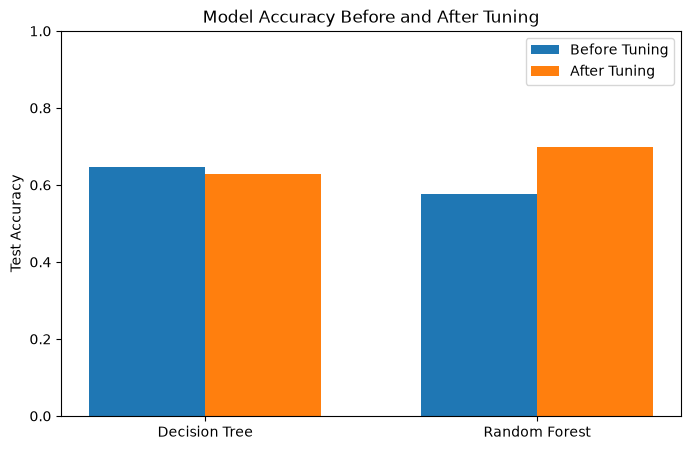

In [63]:
models = ['Decision Tree', 'Random Forest']

before = [dt_before, rf_before]
after = [dt_after, rf_after]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize = (8, 5))

plt.bar(x - width/2, before, width, label = 'Before Tuning')
plt.bar(x + width/2, after, width, label = 'After Tuning')

plt.xticks(x, models)
plt.ylabel('Test Accuracy')
plt.title('Model Accuracy Before and After Tuning')
plt.legend()
plt.ylim(0, 1)

plt.show()

The graph shows that Random Forest improved after hyperparameter tuning, while Decision Tree's accuracy decreased slightly. This may be because the new settings helped Random Forest make better predictions. 

#### Overfitting, Underfitting and Generalisation

In [64]:
# Tuned Decision Tree
dt_train_acc = accuracy_score(y_train, best_dt.predict(X_train))
dt_test_acc = accuracy_score(y_test, best_dt.predict(X_test))

# Tuned Random Forest
rf_train_acc = accuracy_score(y_train, best_rf.predict(X_train))
rf_test_acc = accuracy_score(y_test, best_rf.predict(X_test))

print("Decision Tree Train Accuracy:", dt_train_acc)
print("Decision Tree Test Accuracy:", dt_test_acc)

print("Random Forest Train Accuracy:", rf_train_acc)
print("Random Forest Test Accuracy:", rf_test_acc)

Decision Tree Train Accuracy: 0.8047337278106509
Decision Tree Test Accuracy: 0.6283185840707964
Random Forest Train Accuracy: 0.8224852071005917
Random Forest Test Accuracy: 0.6991150442477876


Decision Tree had 80.47% training accuracy but only 62.83% test accuracy, which suggests overfitting. Random Forest also showed some overfitting, but the difference between its training and test accuracy was smaller. Random Forest performed better on the test data, so it seems to generalise better than Decision Tree.

In [65]:
#To check how both models predict a risk level

sample = X_test.iloc[[0]]

print("Health measurements:")
print(sample)

print("Actual Risk:", y_test.iloc[0])
print("Decision Tree Prediction:", best_dt.predict(sample)[0])
print("Random Forest Prediction:", best_rf.predict(sample)[0])

Health measurements:
     Age  SystolicBP  DiastolicBP   BS  BodyTemp  HeartRate
298   25         120          100  6.8      98.0         60
Actual Risk: mid risk
Decision Tree Prediction: low risk
Random Forest Prediction: low risk


### Feature Importance Analysis

In [66]:
#To check feature importance in Random Forest
import pandas as pd

importance = pd.Series(best_rf.feature_importances_,index = X_train.columns)

print(importance.sort_values(ascending = False))

BS             0.389802
SystolicBP     0.211712
BodyTemp       0.138101
Age            0.100775
DiastolicBP    0.090138
HeartRate      0.069473
dtype: float64


In [67]:
#To check feature importance in Decision Tree

dt_importance = pd.Series(best_dt.feature_importances_, index = X_train.columns)

print(dt_importance.sort_values(ascending = False))

BS             0.538794
SystolicBP     0.226982
BodyTemp       0.143639
HeartRate      0.050108
DiastolicBP    0.021335
Age            0.019143
dtype: float64


Both Decision Tree and Random Forest identified blood sugar (BS) as the most important feature. BS had an importance score of 53.88% in Decision Tree and 38.98% in Random Forest. Systolic blood pressure was the second most important feature in both models. Just because BS was the most important feature in the model does not mean that higher blood sugar always causes high risk. It simply shows a pattern that the model learned from the data.

### Conclusion

In this project, I used Decision Tree and Random Forest to predict maternal health risk levels. I tested both models using different data splits, cross-validation and hyperparameter tuning. The results showed that Random Forest performed better after tuning, with a test accuracy of 69.91%, compared to 62.83% for Decision Tree. Both models showed some signs of overfitting, but Random Forest performed better on the test data. Overall, I would choose Random Forest for this dataset, although its accuracy could still be improved.

### References
1. Ahmed, M. (2020) Maternal Health Risk [Dataset]. UCI Machine Learning Repository. Available at: https://archive.ics.uci.edu/dataset/863/maternal+health+risk
2. Kavlakoglu, E. (2021) 'What is a decision tree?', IBM Think, 2 November. Available at: https://www.ibm.com/think/topics/decision-trees
3. Kavlakoglu, E. (2021) 'What is random forest?', IBM Think, 20 October. Available at: https://www.ibm.com/think/topics/random-forest